# Exercise 01 — Statistical Graphs with Python

A dataset can contain thousands of values, making patterns difficult to recognise by reading a table. **Graphs translate those values into a visual form** so that we can compare measurements, identify changes and ask new questions. The type of graph matters because different representations reveal different aspects of the same data.

In this exercise, we will create three graphs:

- A **line graph** to follow galvanic skin response (GSR) readings through a recorded sequence.
- A **bar chart** to compare how frequently different tags appear in Flickr photographs.
- A **histogram** to examine the distribution of Flickr's geographical accuracy values.

We will use **Pandas** to organise the data, **Seaborn** to produce statistical plots and **Matplotlib** to control labels and save the figures. Seaborn builds on Matplotlib and works directly with Pandas DataFrames.

![Seaborn logo](https://seaborn.pydata.org/_static/logo-wide-lightbg.svg)

You can explore other graph types in the [Seaborn example gallery](https://seaborn.pydata.org/examples/index.html).

## Installation

If these libraries are not installed in your Python environment, run this command in a notebook cell:

```python
%pip install pandas seaborn matplotlib
```

The example datasets are stored in this exercise's `assets` folder. Run the notebook from its own folder so that the relative paths work.

## Line Graph — GSR Measurements

Our first dataset records measurements taken during a walk. **GSR** (galvanic skin response), also called electrodermal activity, relates to changes in the skin's electrical properties. The file also includes location and time information.

We will plot the `GSR` column against `Count`, which numbers the recorded samples. This shows **how the readings change over the sequence**, not their exact timing or location. We should not interpret individual peaks as specific emotions: without knowing the sensor's calibration and the conditions of recording, these values are simply the recorded sensor readings.

First, load the tab-separated file into a Pandas DataFrame:

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# The dataset is stored alongside this notebook
gsr_df = pd.read_csv("assets/010RC14X.CSV", sep="\t")

gsr_df.head()

In [ ]:
# A line graph follows each GSR reading in measurement order
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(10, 4))
sns.lineplot(
    data=gsr_df,
    x="Count",
    y="GSR",
    estimator=None,
    ax=ax
)

ax.set_title("GSR readings during a walk")
ax.set_xlabel("Measurement number")
ax.set_ylabel("GSR reading (sensor units)")

fig.tight_layout()
fig.savefig("lineplot.pdf")
plt.show()

The line connects readings in their recorded order. We use `estimator=None` so that Seaborn plots the individual observations rather than calculating an average for repeated x-values. The labels tell the reader what the axes represent; the units are left as **sensor units** because this example does not establish a calibration.

The command `fig.savefig("lineplot.pdf")` exports the graph as a vector PDF. This can be placed into **Adobe Illustrator or InDesign** for further graphic development.

**Alternative:** If you would rather design the graph in another program, you can export just the measurement column as a CSV:

In [ ]:
# Export the GSR values as a simple, one-column table
gsr_df[["GSR"]].to_csv("GSR.csv", index=False)

## Bar Plot

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


df = pd.read_csv(r"assets\Flickr.csv")
df.head(3)


,p_id,lat,lon,o_id,p_date,accuracy,title,tags,url
0,214028,51.504265,-0.078659,51035570500@N01,2003-05-24 17:40:38,16,"City Hall, London",london england normanfoster architecture geota...,https://live.staticflickr.com/1/214028_a96ba3e...
1,436102,51.505937,-0.082182,40385587@N00,2004-03-16 14:02:05,14,Angel. A Figurehead,london thames ship olympus c740 figurehead wys...,https://live.staticflickr.com/1/436102_7907e51...
2,436113,51.505323,-0.089650,40385587@N00,2004-03-16 14:04:28,14,Sign at London Bridge Station,signs london olympus lee c740 wysiwyg,https://live.staticflickr.com/1/436113_d87fc68...


Each image can possess numerous tags, located within the "tags" column, separated by a space. To be interpreted by Python, it needs to be converted into a list format, as shown below:

`signs london olympus lee c740 wysiwyg`  &#8594;  `["signs","london","olympus","lee", "c740","wysiwyg"]`

And this is what the `.split()` command does.

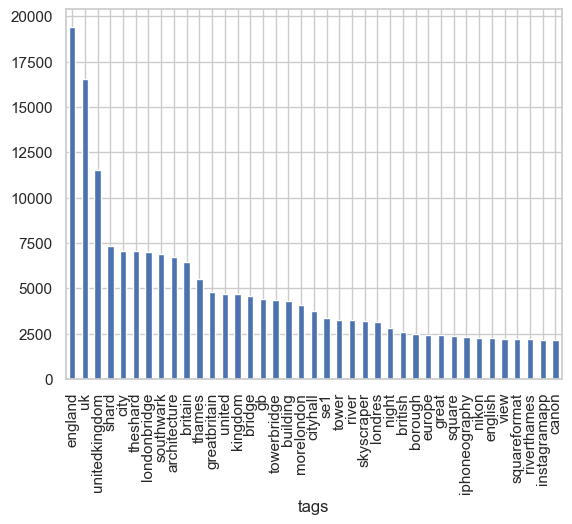

In [19]:
# column_values = df["tags"]
column_values = df["tags"].str.split()

# column_values.head(3)

flat = column_values.explode()
 
counts=flat.value_counts()

dateset=counts.iloc[1:40]
ax = dateset.plot(kind='bar');
#this row saves it as a pdf:
ax.figure.savefig("graph.pdf")

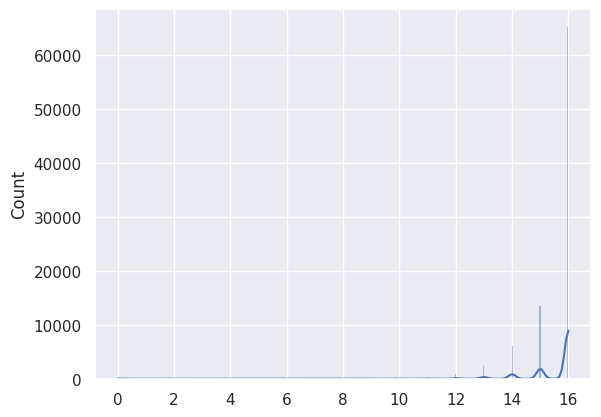

In [25]:
# look at the count of accuracy

listAccuracy = df["accuracy"].tolist()

sns.histplot(listAccuracy, kde=True)
plt.show()